# 07 Évaluation finale (version 1.1)

**Version 1.1** : le U-Net (`unet_effb0_tout`, encodeur EfficientNet-B0, entraîné sur tout le train 150 DPI, notebook 05) suivi du **classifieur des taches** (notebook E4), qui retire les taches prédites jugées fausses ; mesures des racines en millimètres (notebook A3). Tout a été réglé sur le train et le val ; le test est ouvert ici, une seule fois, et ses résultats sont publiés tels quels.

| Jeu de test | Images | Référence |
|---|---|---|
| **Test corrigé** | 50, tirées au hasard dans le test 150 DPI | masques corrigés à la main, sans voir de prédiction : la référence la plus fiable |
| **Grand test 150 DPI** | 4 743 (12 tubes) | annotation PRMI (rectangles), fentes comblées |
| **Test 120 DPI** | 3 542 (7 tubes, autre caméra, autre site, autre année) | annotation PRMI, fentes comblées : généralisation à un autre capteur |

Tous les tubes du test sont absents du train et du val.

**L'essentiel**
- **Segmentation solide et stable** : Dice médian de 0,74 à 0,79 par image sur les trois jeux, y compris sur une autre caméra jamais vue ; du même ordre que la moyenne de 0,77 rapportée sur ces images par le benchmark le plus récent (Smith et al., *Plant Methods*, 2026), sans être directement comparable (références et définitions différentes).
- **Peu de fausses alertes** grâce au classifieur des taches : images sans racine touchées de 33 à 82 % (U-Net seul) à 0 à 20 %, pour 1,2 à 1,5 point de racines trouvées en moins.
- **Mesures en millimètres** : longueur sous-estimée de 23 % (7 % après l'étalonnage fixé sur le val) ; diamètre surestimé de 24 % sur ce test, aux racines particulièrement fines (juste à 2 % près sur le val).
- **Environ 540 images par minute** sur un processeur de portable, sans GPU.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from prmi import blob_classifier as bc, gaps, postprocess as pp, traits as tr, viz
from prmi.dataset import load_lot, test_rows
from prmi.train import (RUNS_DIR, full_logits, key_scores, load_run, postprocess_study, preprocess_full, summarize,
                        timing, trait_scores, v11_loader)

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

NAME = 'unet_effb0_tout'
SCALE = 2

## 1. Prédictions

Le U-Net passe une fois sur chaque image ; sa carte de probabilité donne à la fois la version 1 (seuil 0,5) et la version 1.1 (après le classifieur). Calculé une fois (environ 30 min, clé branchée), puis relu.

In [2]:
model = load_run(NAME)[0]
device = next(model.parameters()).device
clf, TAU = bc.load(RUNS_DIR / NAME / 'classifieur_taches.joblib')
OPTIONS = bc.v11_options(clf, TAU)

test_items = load_lot('test', SCALE)                       # 50 images, masques corrigés
rows150, rows120 = test_rows(150), test_rows(120)
for rows in (rows150, rows120):
    gaps.save_filled(rows)                                 # fentes de l'annotation PRMI comblées (déjà fait : rien)
runs = {'test corrigé': postprocess_study(NAME, 'test_corrige_v11', OPTIONS, items=test_items),
        'grand test 150 DPI': postprocess_study(NAME, 'test_150_v11', OPTIONS, rows=rows150),
        'test 120 DPI': postprocess_study(NAME, 'test_120_v11', OPTIONS, rows=rows120)}
v11 = {k: r[r['variante'] == 'U-Net + classifieur'] for k, r in runs.items()}

## 2. Segmentation

Par image : Dice (recouvrement des surfaces), clDice (continuité des racines) et erreur de longueur sur les images avec racine ; part des images sans racine où le modèle détecte quelque chose.

,images,avec racine,Dice médian,Dice global,clDice médian,erreur de longueur médiane,racines trouvées,images vides touchées
test corrigé,50.0,32.0,0.79,0.77,0.84,0.20,0.80,0.00
grand test 150 DPI,4743.0,2765.0,0.74,0.73,0.85,0.21,0.67,0.13
test 120 DPI,3542.0,1683.0,0.79,0.75,0.88,0.25,0.85,0.20


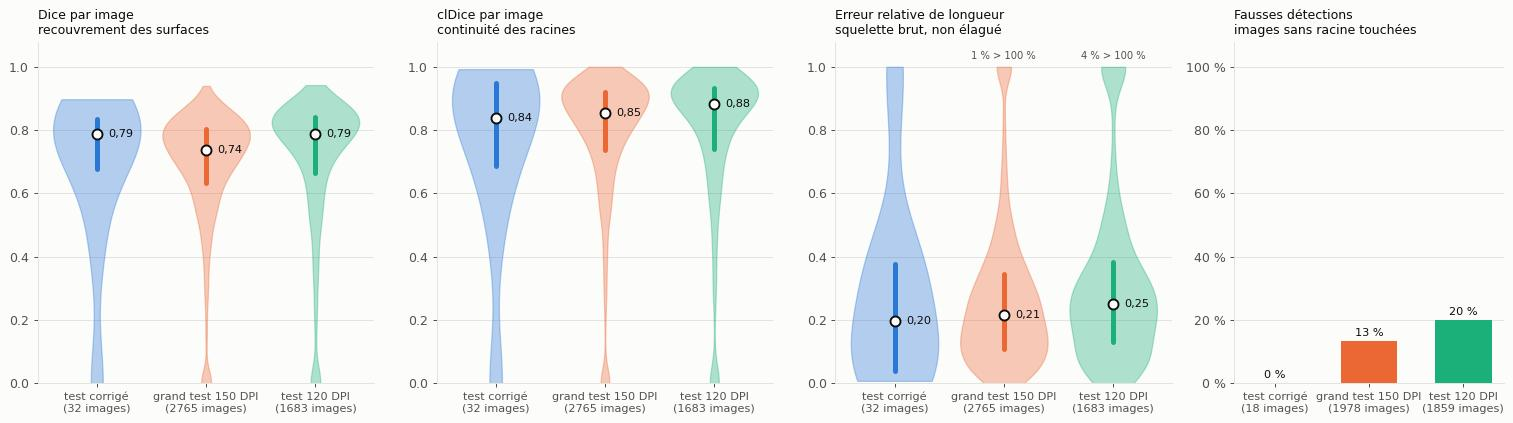

In [3]:
viz.save(viz.plot_test_results(v11), 'test_resultats.png')
pd.DataFrame({k: key_scores(t) for k, t in v11.items()}).T.round(2)

## 3. Ce qu'apporte le classifieur

Version 1 (U-Net seul) et version 1.1 (U-Net + classifieur des taches), sur les mêmes images.

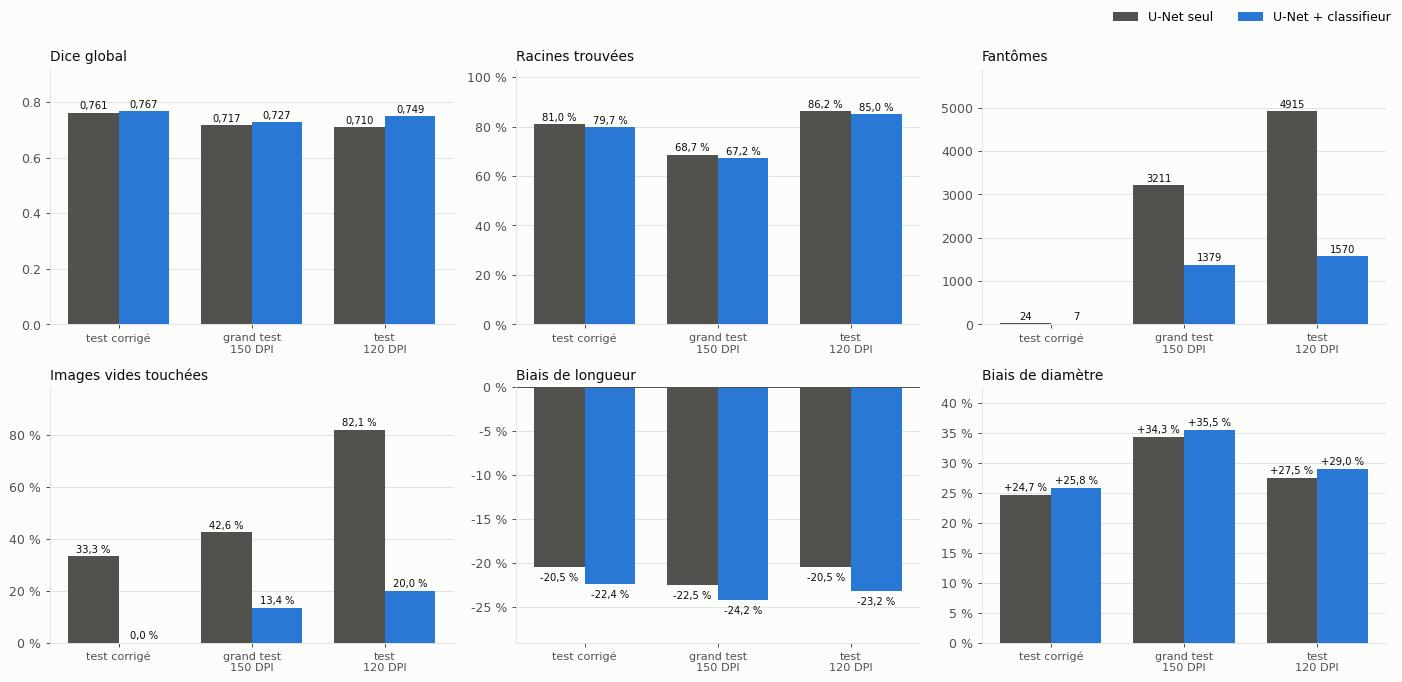

In [4]:
METRICS = ['global_dice', 'roots_found', 'ghosts', 'fp_empty', "longueur : biais d'ensemble", "diamètre : biais d'ensemble"]
compare = {k: pd.DataFrame({v: {**summarize(g), **trait_scores(g)} for v, g in r.groupby('variante', sort=False)}).T[METRICS]
           for k, r in runs.items()}
viz.save(viz.plot_compare_sets(compare, METRICS), 'test_avec_sans_classifieur.png')

## 4. Mesures en millimètres

Sur le test corrigé (32 images avec racine, référence corrigée à la main), avec la chaîne du notebook A3 : longueur = squelette du masque, diamètre = deux fois la distance au bord le long du squelette, échelle de 40,9 px/mm (vérifiée dans A3 ; le « 150 DPI » annoncé est faux). Puis le facteur d'étalonnage de la longueur, fixé sur le val, appliqué aux totaux.

,longueur : erreur médiane,longueur : biais,diamètre : erreur médiane,diamètre : biais
mesure brute,0.208,-0.229,0.149,0.243
longueur étalonnée (x 1.2),0.231,-0.075,0.149,0.243


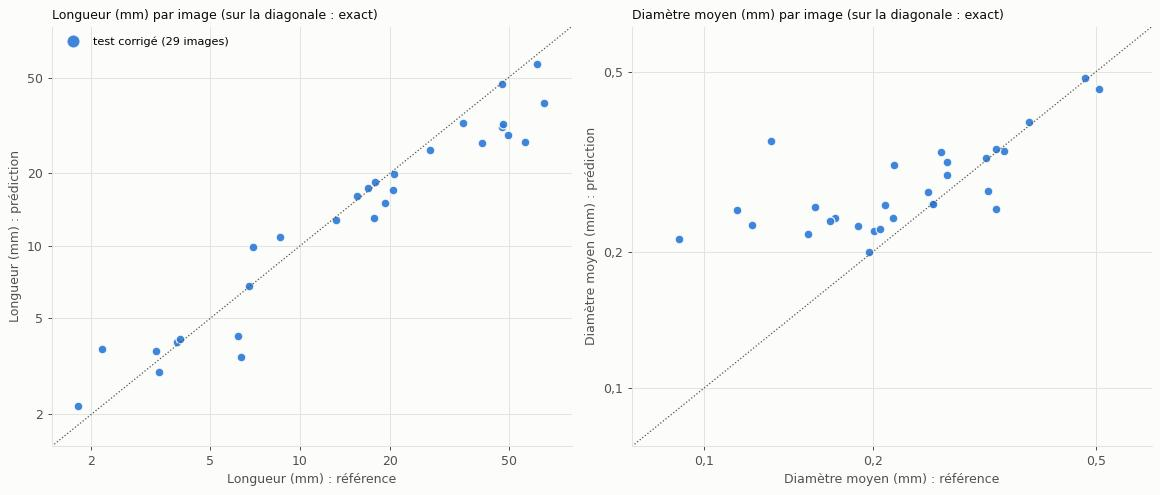

In [5]:
PPM = tr.px_per_mm(150)
rooted = [it for it in test_items if it['mask_full'].any()]
with torch.no_grad():
    probs = [torch.sigmoid(full_logits(model, it, device)[0])[0, 0].cpu().numpy() for it in rooted]
mm = tr.compare([bc.classifier_filter(p, clf, TAU) for p in probs], [it['mask_full'] for it in rooted], PPM)
viz.save(viz.plot_traits({'test corrigé': mm}, unit='mm'), 'test_traits_mm.png')
calibrated = mm.assign(**{'longueur prédite': mm['longueur prédite'] * tr.LENGTH_FACTOR})
pd.DataFrame({'mesure brute': tr.errors(mm), f'longueur étalonnée (x {tr.LENGTH_FACTOR})': tr.errors(calibrated)}).T.round(3)

**À retenir**
- **Longueur** : sous-estimée de 23 % en brut (17 % sur le val), à cause des racines que le modèle ne détecte pas. Le facteur d'étalonnage fixé sur le val (x 1,2) ramène le biais des totaux à -7,5 % ; il corrige l'essentiel, mais pas tout : la part de racines manquées varie d'un jeu à l'autre. L'erreur par image reste d'environ 20 % : la longueur est fiable en total (par tube, par date), moins image par image.
- **Diamètre** : +24 % sur ce test, alors qu'il était juste à 2 % près sur le val. Les racines du test sont plus fines (environ 0,18 mm contre 0,22 mm dans l'annotation PRMI), et le modèle, qui travaille à demi-résolution, élargit les racines très fines (notebook A3). Le diamètre est donc fiable pour des racines d'au moins 0,25 mm environ, surestimé en dessous. Piste : prédire à pleine résolution pour les racines fines.
- **Échelle** : 40,9 px/mm, vérifiée sur les données (notebook A3), au lieu des 5,9 px/mm annoncés : sans cette vérification, toutes les mesures auraient été fausses d'un facteur 7.

## 5. Où se trompe le modèle

Dice par image selon la quantité de racine dans l'image (grands tests) : les erreurs se concentrent sur les images qui ne contiennent que quelques fragments de racine.

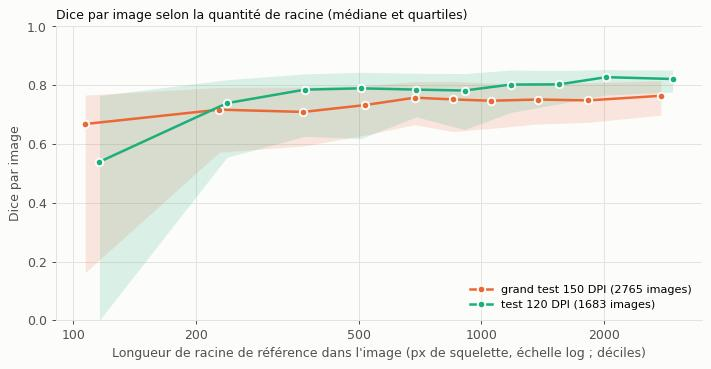

In [6]:
viz.save(viz.plot_by_amount({k: t for k, t in v11.items() if k != 'test corrigé'}, viz.TEST_COLORS[1:]),
         'test_dice_selon_quantite.png')

## 6. Vitesse

Sur 50 images du grand test, lues sur la clé, avec le processeur du portable (sans GPU) : lecture et prétraitement, U-Net, puis classifieur des taches.

In [7]:
speed = timing(model, rows150, device)
t0 = time.perf_counter()
for p in probs:
    bc.classifier_filter(p, clf, TAU)
speed['classifieur (s / image)'] = (time.perf_counter() - t0) / len(probs)
total = speed['lecture et prétraitement (s / image)'] + speed['modèle (s / image)'] + speed['classifieur (s / image)']
speed['images par minute'] = 60 / total
pd.Series(speed).to_frame('').T

,lecture et prétraitement (s / image),modèle (s / image),images par minute,processeur,classifieur (s / image)
,0.009938,0.062479,537.52835,"16 fils, cpu",0.039206


## 7. Images

Au curseur, du plus bas Dice au plus haut, images sans racine à la fin (de la plus touchée à la moins touchée) : image, référence, prédiction de la version 1.1. Test corrigé d'abord, puis les grands tests (images relues sur la clé et prédiction recalculée à chaque position, clé branchée).

In [ ]:
with torch.no_grad():
    corrected = {}
    for it in test_items:
        p = torch.sigmoid(full_logits(model, it, device)[0])[0, 0].cpu().numpy()
        corrected[it['name']] = (preprocess_full(it), it['mask_full'], bc.classifier_filter(p, clf, TAU))
viz.browse_loaded(v11['test corrigé'], corrected.get)

In [ ]:
viz.browse_loaded(v11['grand test 150 DPI'], v11_loader(model, clf, TAU, rows150))

In [ ]:
viz.browse_loaded(v11['test 120 DPI'], v11_loader(model, clf, TAU, rows120))